# W1: Black–Scholes with discrete hedging and costs

In W1 the stock follows Black–Scholes with constant 20% volatility and no jumps, options are priced at that volatility, and the hedger uses the same model. Any hedging error left therefore comes only from discrete rebalancing and trading costs.

We sell one ATM call with 30 calendar days (21 trading days) to expiry, $S_0 = 100$, and hedge it to expiry. We simulate 10,000 paths on a 5-minute grid (78 steps a day) and hedge the same paths at frequencies from once a day to every 5 minutes, so differences between frequencies are not sampling noise.

Hedging error is premium − payoff + hedge gains − trading costs (negative is a loss), in price units, so 0.5 is 0.5% of $S_0$. `per_day` is rebalances per day, stock costs are proportional to traded value, and turnover is stock traded in units of $S_0$.

Strategies: `delta` (plain BS delta); `leland` (delta at Leland's slightly higher volatility, so it trades less); `whalley_wilmott` (no-trade band around delta, trading back to the band edge only when the holding leaves it); `delta_gamma` and `delta_vega` (also trade a 42-day ATM call to zero gamma or vega; the option costs 1% of its price to trade, free in zero-cost runs).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# hedging is this project's own code, in src/hedging/
from hedging import bs, experiments, generator, hedge, worlds

pd.set_option("display.precision", 4)
# figures are saved to results/figures/
FIG = experiments.RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

## 1. Full grid

Every strategy on the same paths at 6 frequencies and 4 cost levels (0, 1, 5, 10 bp), one row per combination. The full table is in `results/w1_grid.csv`; we show the first five rows. `mean` turns negative with costs, since they are a steady drag.

In [2]:
# m: the simulated market; table: one row per strategy x frequency x cost level
m, table = experiments.w1()
# writes results/w1_grid.csv
experiments.save(table, "w1_grid")
table.head()

,world,per_day,cost_bp,strategy,rmse,cvar95,mean,std,turnover
0,W1 Black-Scholes,1,0,delta,0.4308,1.0024,0.0081,0.4307,2.4375
1,W1 Black-Scholes,1,0,delta_gamma,0.0923,0.1841,0.0006,0.0923,2.8004
2,W1 Black-Scholes,1,0,delta_vega,0.3262,0.7897,0.0052,0.3262,1.7862
3,W1 Black-Scholes,1,1,delta,0.4322,1.0335,-0.0163,0.4319,2.4375
4,W1 Black-Scholes,1,1,delta_gamma,0.2470,0.5150,-0.2101,0.1297,2.8004


## 2. Check against Derman–Kamal

With no costs, the error of a delta hedge on an ATM option rebalanced $N$ times has a standard deviation of about $\sqrt{\pi/4}\,\mathcal{V}\sigma/\sqrt{N}$ (Derman–Kamal), where $\mathcal{V}$ is the option's vega. Matching it is a check on the hedging code. `n_steps` is $N$ (21 × `per_day`) and `ratio` is simulated `std` over `derman_kamal`. The plot is log–log, so $1/\sqrt{N}$ is a straight line.

,per_day,std,rmse,mean,n_steps,derman_kamal,ratio
0,1,0.4307,0.4308,0.0081,21,0.4452,0.9674
18,2,0.3064,0.3065,0.0075,42,0.3148,0.9732
36,6,0.1777,0.1777,0.0029,126,0.1818,0.9773
54,13,0.1227,0.1227,0.0005,273,0.1235,0.9937
72,26,0.0865,0.0865,0.0005,546,0.0873,0.9909
90,78,0.0491,0.0491,0.0007,1638,0.0504,0.9747


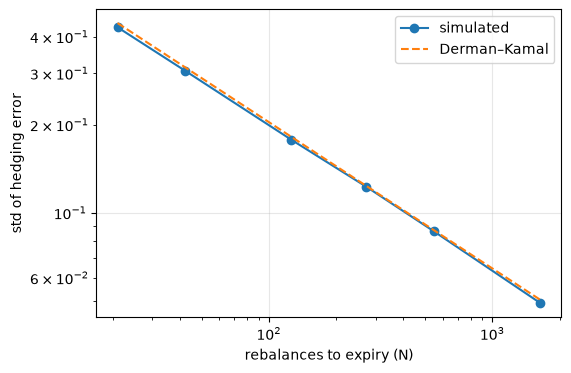

In [3]:
# zero-cost delta hedge, one row per rebalancing frequency
dk = table[(table.strategy == "delta") & (table.cost_bp == 0)][["per_day", "std", "rmse", "mean"]].copy()
dk["n_steps"] = dk.per_day * worlds.DAYS
dk["derman_kamal"] = bs.derman_kamal_std(100.0, 100.0, worlds.T, 0.2, dk.n_steps)
# 1.0 means simulation and formula agree exactly
dk["ratio"] = dk["std"] / dk.derman_kamal
display(dk)

# log-log chart: the 1/sqrt(N) rule is a straight line
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(dk.n_steps, dk["std"], "o-", label="simulated")
ax.loglog(dk.n_steps, dk.derman_kamal, "--", label="Derman–Kamal")
ax.set_xlabel("rebalances to expiry (N)"); ax.set_ylabel("std of hedging error"); ax.legend(); ax.grid(alpha=.3)
fig.savefig(FIG / "w1_derman_kamal.png", dpi=150, bbox_inches="tight")

The simulation matches the formula at every frequency, with `ratio` between 0.967 (daily) and 0.994 (13 a day). Going from daily to 5-minute rebalancing cuts the error from 0.4307 to 0.0491, about √78 ≈ 8.8 times smaller. Without costs more frequent hedging always helps, but halving the error takes four times as many rebalances.

## 3. Rebalancing frequency under costs

Costs push the mean error below zero while infrequent hedging widens its spread. RMSE captures both, so each cost level has its own best frequency. For the plain delta hedge we plot RMSE and CVaR 95% against rebalances per day (log scale), one line per cost level. The table is RMSE by frequency (rows) and cost (columns).

cost_bp,0,1,5,10
per_day,,,,
1,0.4308,0.4322,0.4522,0.5054
2,0.3065,0.3086,0.3473,0.4450
6,0.1777,0.1844,0.2995,0.5127
13,0.1227,0.1404,0.3539,0.6730
26,0.0865,0.1246,0.4544,0.8958
78,0.0491,0.1547,0.7365,1.4710


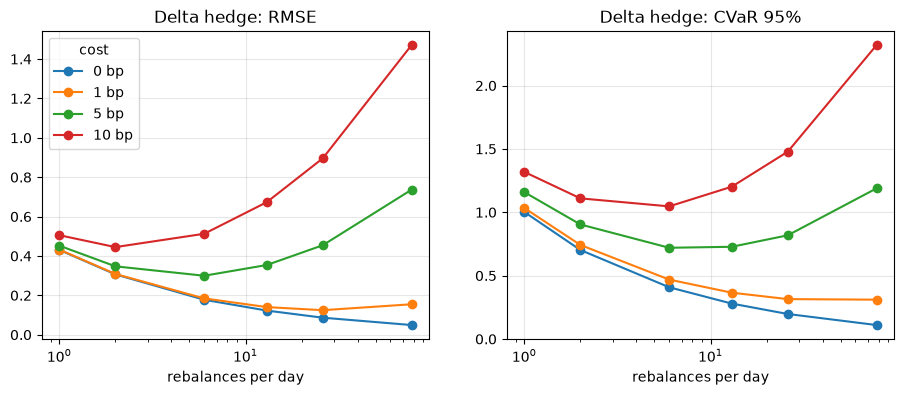

In [4]:
# plain delta hedge only
delta = table[table.strategy == "delta"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for bp, g in delta.groupby("cost_bp"):
    axes[0].plot(g.per_day, g.rmse, "o-", label=f"{bp} bp")
    axes[1].plot(g.per_day, g.cvar95, "o-", label=f"{bp} bp")
for ax, name in zip(axes, ["RMSE", "CVaR 95%"]):
    ax.set_xscale("log"); ax.set_xlabel("rebalances per day"); ax.set_title(f"Delta hedge: {name}"); ax.grid(alpha=.3)
axes[0].legend(title="cost")
fig.savefig(FIG / "w1_frequency_cost.png", dpi=150, bbox_inches="tight")
# RMSE table: rows = rebalances per day, columns = cost in bp
delta.pivot(index="per_day", columns="cost_bp", values="rmse")

The best of the six tested frequencies falls as costs rise:

| Cost | Best frequency | RMSE there |
|---|---|---|
| 0 bp | 78 a day (every 5 minutes) | 0.0491 |
| 1 bp | 26 a day | 0.1246 |
| 5 bp | 6 a day | 0.2995 |
| 10 bp | 2 a day | 0.4450 |

At 10 bp, rebalancing every 5 minutes gives an RMSE of 1.4710, more than three times the 0.4450 from rebalancing twice a day.

## 4. Strategy comparison

RMSE by (cost in bp, rebalances per day) and strategy. Leland and Whalley–Wilmott reduce to plain delta at zero cost, so they are not run there (`NaN`).

In [5]:
# RMSE: rows = (cost, rebalances per day), one column per strategy
table.pivot_table(index=["cost_bp", "per_day"], columns="strategy", values="rmse")

strategy          delta  delta_gamma  delta_vega  leland  whalley_wilmott
cost_bp per_day                                                          
0       1        0.4308       0.0923      0.3262     NaN              NaN
        2        0.3065       0.0578      0.2342     NaN              NaN
        6        0.1777       0.0273      0.1383     NaN              NaN
        13       0.1227       0.0154      0.0962     NaN              NaN
        26       0.0865       0.0086      0.0677     NaN              NaN
        78       0.0491       0.0038      0.0385     NaN              NaN
1       1        0.4322       0.2470      0.3380  0.4322           0.4836
        2        0.3086       0.3118      0.2537  0.3085           0.3733
        6        0.1844       0.4980      0.1923  0.1839           0.2688
        13       0.1404       0.7117      0.2026  0.1385           0.2237
        26       0.1246       0.9868      0.2455  0.1208           0.1987
        78       0.1547       1.6768      0.3855  0.1442           0.1758
5       1        0.4522       0.3653      0.3673  0.4514           0.5604
        2        0.3473       0.4841      0.3068  0.3447           0.4626
        6        0.2995       0.7939      0.3173  0.2879           0.3713
        13       0.3539       1.1421      0.4001  0.3277           0.3330
        26       0.4544       1.5884      0.5244  0.4083           0.3134
        78       0.7365       2.7063      0.8540  0.6267           0.2962
10      1        0.5054       0.5175      0.4229  0.5017           0.6267
        2        0.4450       0.7011      0.4005  0.4342           0.5381
        6        0.5127       1.1646      0.4973  0.4751           0.4573
        13       0.6730       1.6813      0.6609  0.5969           0.4247
        26       0.8958       2.3424      0.8824  0.7626           0.4087
        78       1.4710       3.9969      1.4498  1.1548           0.3952

The same layout for CVaR 95%.

In [6]:
# CVaR 95%, same layout
table.pivot_table(index=["cost_bp", "per_day"], columns="strategy", values="cvar95")

strategy          delta  delta_gamma  delta_vega  leland  whalley_wilmott
cost_bp per_day                                                          
0       1        1.0024       0.1841      0.7897     NaN              NaN
        2        0.7023       0.1257      0.5638     NaN              NaN
        6        0.4081       0.0562      0.3338     NaN              NaN
        13       0.2795       0.0334      0.2305     NaN              NaN
        26       0.1973       0.0187      0.1620     NaN              NaN
        78       0.1101       0.0072      0.0892     NaN              NaN
1       1        1.0335       0.5150      0.8717  1.0278           1.0860
        2        0.7421       0.6291      0.6628  0.7343           0.8258
        6        0.4688       1.0204      0.4801  0.4553           0.6005
        13       0.3655       1.5150      0.4394  0.3434           0.4993
        26       0.3147       2.1452      0.4778  0.2830           0.4444
        78       0.3104       3.7502      0.7122  0.2485           0.3976
5       1        1.1589       0.7085      0.9685  1.1297           1.2675
        2        0.9038       0.9387      0.7926  0.8618           1.0546
        6        0.7199       1.6270      0.6948  0.6416           0.8602
        13       0.7277       2.4580      0.7533  0.5921           0.7787
        26       0.8183       3.5041      0.9094  0.6104           0.7353
        78       1.1889       6.1666      1.4220  0.7558           0.6987
10      1        1.3184       0.9636      1.0941  1.2576           1.4338
        2        1.1098       1.3354      0.9631  1.0210           1.2481
        6        1.0466       2.3901      0.9753  0.8704           1.0757
        13       1.2016       3.6439      1.1636  0.8908           1.0031
        26       1.4782       5.2125      1.4796  0.9938           0.9645
        78       2.3196       9.2023      2.3889  1.3157           0.9351

Without costs delta–gamma is far ahead (0.0923 against 0.4308 for delta at daily rebalancing), since cancelling gamma removes most of the discretisation error. With costs it gets worse the more it trades, because each option rebalance costs 1% of its price: at 1 bp its RMSE is 1.6768 at 78 a day, but 0.2470 at once a day, the best of the five.

Once costs matter the cost-aware strategies do best. The lowest RMSE is Leland at 1 bp (0.1208, 26 a day) and 5 bp (0.2879, 6 a day), and Whalley–Wilmott at 10 bp (0.3952, 78 a day). Leland has the lowest CVaR 95% at every cost level (e.g. 0.8704 at 10 bp, 6 a day).

Whalley–Wilmott's error keeps falling with frequency at every cost level, because the band rather than the clock decides when to trade, whereas plain delta gets much worse at high frequency once trades cost money.